# A first quantum classifier: the Quantum Convolutional Neural Network (QCNN)

This notebook shows, step by step, how a quantum circuit becomes a **trainable layer** inside an ordinary PyTorch model, and how to check honestly whether that layer helps.

**What you will see**
1. A hybrid model: a classical linear layer compresses an image into a few numbers, those numbers set the rotation angles of qubits, and a small quantum circuit (convolution + pooling, after Cong, Choi, & Lukin, 2019) turns them into one prediction.
2. The same training loop for every model, so that the only difference between models is the model itself.
3. Three classical reference models, including one with the **same number of trainable parameters** as the quantum circuit.

**Everything runs on a laptop CPU.** The quantum circuit is simulated exactly with [PennyLane](https://pennylane.ai); no quantum hardware or account is needed.

Reference: Cong, I., Choi, S., & Lukin, M. D. (2019). Quantum convolutional neural networks. *Nature Physics, 15*(12), 1273–1278. https://doi.org/10.1038/s41567-019-0648-8

## 0. Setup

Required packages: `pennylane torch torchvision scikit-learn matplotlib pandas`. On Google Colab, install them first in a new cell with `%pip install pennylane torchvision` (the others are preinstalled).

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from torchvision.datasets import CIFAR10, MNIST

DATA_ROOT = "./data"
SEEDS = [2024, 2025, 2026]  # every experiment is repeated with three random seeds
LR_GRID = [1e-3, 1e-2]  # every neural model gets the same two learning rates; the better one on validation is kept
BATCH_SIZE = 32


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print("PennyLane", qml.__version__, "| PyTorch", torch.__version__)

PennyLane 0.42.3 | PyTorch 2.9.1+cu130


## 1. Data: two-class image problems

- **MNIST** digits 0 vs 1 (28×28 grey images, 784 numbers per image).
- **CIFAR-10** airplane vs automobile (32×32 colour images, 3,072 numbers per image).

The training set is deliberately small (70 MNIST images, 700 CIFAR-10 images). Validation and test images come from the official test split, so they never overlap with training. The test set has 1,000 images so that the reported AUROC is not driven by a handful of images.

In [2]:
def load_binary_images(name, classes, n_train, n_val, n_test, seed):
    """Return (X_train, y_train), (X_val, y_val), (X_test, y_test).

    X is a float tensor of shape (N, n_pixels) with values in [0, 1];
    y is 1 for classes[1] and 0 for classes[0].
    """
    dataset = MNIST if name == "MNIST" else CIFAR10
    train_raw = dataset(DATA_ROOT, train=True, download=True)
    test_raw = dataset(DATA_ROOT, train=False, download=True)

    def to_xy(ds):
        X = torch.as_tensor(np.asarray(ds.data), dtype=torch.float32) / 255.0
        y = torch.as_tensor(np.asarray(ds.targets))
        keep = (y == classes[0]) | (y == classes[1])
        X, y = X[keep], (y[keep] == classes[1]).long()
        return X.reshape(len(X), -1), y

    X_tr, y_tr = to_xy(train_raw)
    X_te, y_te = to_xy(test_raw)

    g = torch.Generator().manual_seed(seed)
    i_tr = torch.randperm(len(X_tr), generator=g)[:n_train]
    i_te = torch.randperm(len(X_te), generator=g)
    i_va, i_ts = i_te[:n_val], i_te[n_val : n_val + n_test]
    return (X_tr[i_tr], y_tr[i_tr]), (X_te[i_va], y_te[i_va]), (X_te[i_ts], y_te[i_ts])

## 2. The quantum model

**How a quantum circuit becomes a layer**
- A qubit's state is set by rotation angles. We write the input numbers into these angles (*angle embedding*).
- The circuit then applies gates whose angles are **trainable parameters**, exactly like the weights of a neural network.
- Measuring a qubit returns a number between −1 and +1 (the expectation value ⟨Z⟩). Gradients of this number with respect to every gate angle are computed automatically, so PyTorch can train the circuit with the usual optimizer.

**The QCNN circuit**
- *Convolution*: the same kind of two-qubit block (single-qubit rotations U3 and two-qubit couplings IsingXX, IsingYY, IsingZZ) acts on neighbouring pairs of qubits.
- *Pooling*: every second qubit is measured, and the result controls a rotation on its neighbour; the measured qubit is then dropped. Each pooling layer halves the number of qubits.
- After two convolution + pooling layers, one qubit is measured and gives the prediction.

**The hybrid model** = classical linear layer (pixels → `n_qubits` numbers) → quantum circuit → ⟨Z⟩ → one learnable scale and offset → logit.

In [3]:
class QCNN(nn.Module):
    """Hybrid quantum convolutional neural network for binary classification."""

    def __init__(self, input_dim: int, n_qubits: int = 4, n_layers: int = 2):
        super().__init__()
        self.n_qubits, self.n_layers = n_qubits, n_layers

        self.fc = nn.Linear(input_dim, n_qubits)  # classical compression: pixels -> qubit angles
        self.conv_params = nn.Parameter(torch.randn(n_layers, n_qubits, 18))
        self.pool_params = nn.Parameter(torch.randn(n_layers, n_qubits // 2, 3))
        self.readout = nn.Linear(1, 1)  # logit = a * <Z> + b, two parameters

        device = qml.device("default.qubit", wires=n_qubits)
        self.qnode = qml.qnode(device, interface="torch")(self.circuit)

    def circuit(self, features, conv_weights, pool_weights):
        wires = list(range(self.n_qubits))
        qml.AngleEmbedding(features, wires=wires, rotation="Y")
        for layer in range(self.n_layers):
            self._convolution(conv_weights[layer], wires)
            self._pooling(pool_weights[layer], wires)
            wires = wires[::2]  # keep every second qubit after pooling
        return qml.expval(qml.PauliZ(wires[0]))

    @staticmethod
    def _convolution(weights, wires):
        """Two-qubit blocks on neighbouring pairs: first pairs (0,1),(2,3),..., then (1,2),(3,4),..."""
        n_wires = len(wires)
        for parity in (0, 1):
            for i, w in enumerate(wires):
                if i % 2 == parity and i < n_wires - 1:
                    qml.IsingXX(weights[i, 3], wires=[w, wires[i + 1]])
                    qml.IsingYY(weights[i, 4], wires=[w, wires[i + 1]])
                    qml.IsingZZ(weights[i, 5], wires=[w, wires[i + 1]])
                    qml.U3(*weights[i, 6:9], wires=w)
                    qml.U3(*weights[i, 9:12], wires=wires[i + 1])

    @staticmethod
    def _pooling(weights, wires):
        """Measure every second qubit; the outcome controls a rotation on its left neighbour."""
        for i, w in enumerate(wires):
            if i % 2 == 1:
                outcome = qml.measure(w)
                qml.cond(outcome, qml.U3)(*weights[i // 2], wires=wires[i - 1])

    def forward(self, x):
        z = self.qnode(self.fc(x), self.conv_params, self.pool_params)  # shape (batch,)
        return self.readout(z.float().unsqueeze(-1)).squeeze(-1)


def count_used_quantum_parameters(n_qubits: int, n_probes: int = 8) -> int:
    """Count circuit angles that can influence the output.

    The parameter tensors are allocated generously (18 angles per qubit), but the circuit uses
    only some of them, and a rotation about Z right before a Z measurement cannot change the
    result. An angle counts as used if its gradient is clearly non-zero (> 1e-8) for at least one
    of several random circuits and inputs. The probe uses its own fixed seed, so the count is the
    same in every run.
    """
    g = torch.Generator().manual_seed(0)
    used = None
    for _ in range(n_probes):
        torch.manual_seed(int(torch.randint(0, 10**6, (1,), generator=g)))
        model = QCNN(input_dim=8, n_qubits=n_qubits)
        model(torch.rand(4, 8, generator=g)).sum().backward()
        mask = [p.grad.abs() > 1e-8 for p in (model.conv_params, model.pool_params)]
        used = mask if used is None else [u | m for u, m in zip(used, mask)]
    return int(sum(int(m.sum()) for m in used))

Draw the circuit once (for 4 qubits). This is the picture used in the slides.

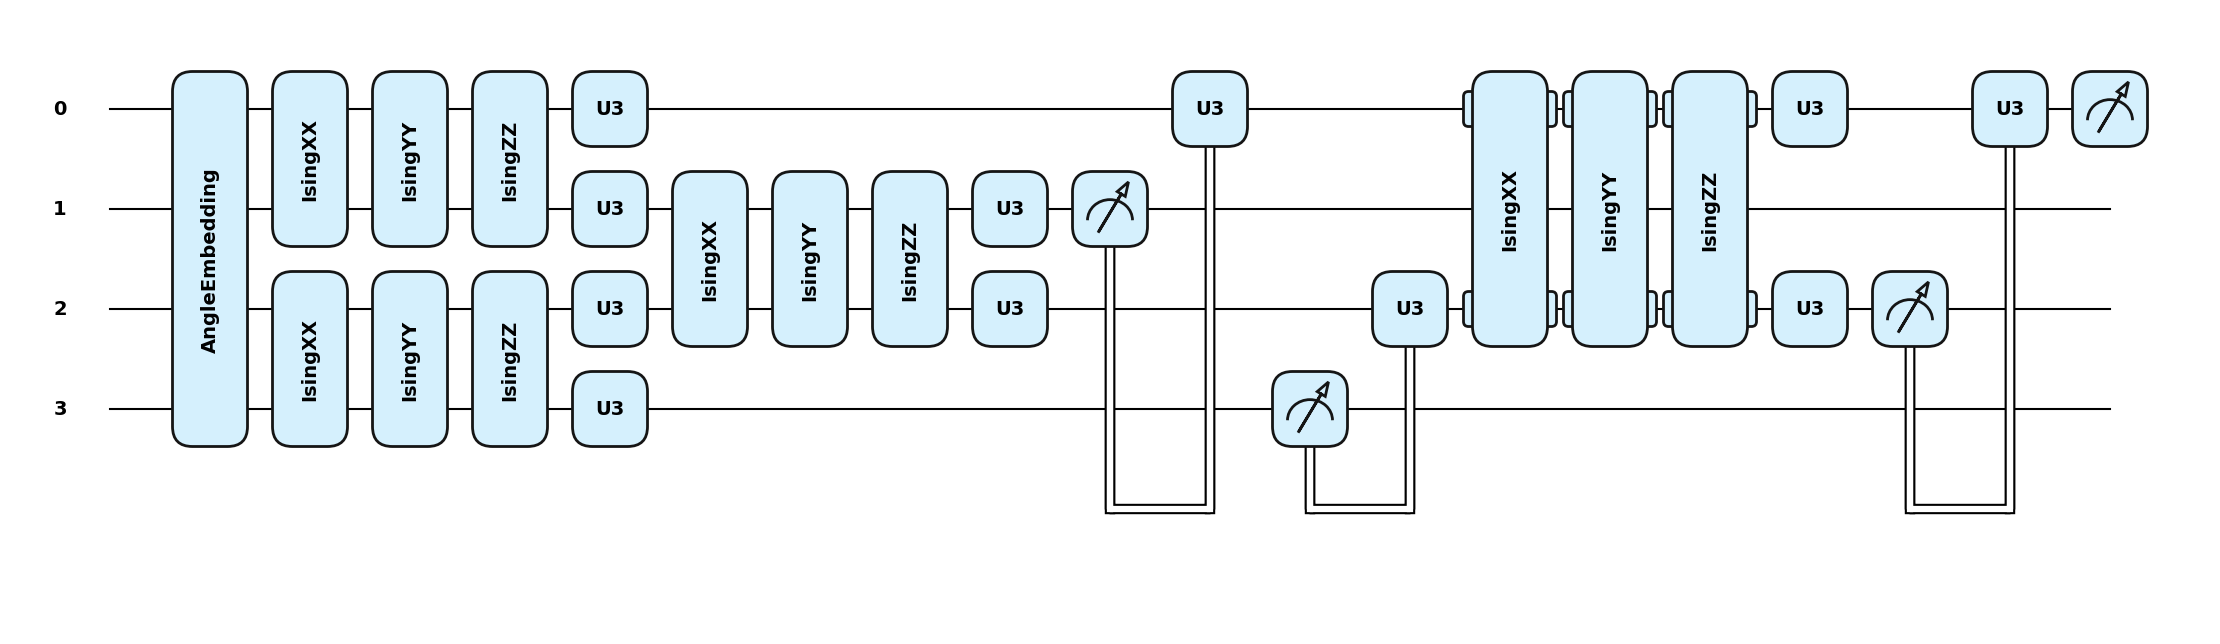

In [4]:
demo = QCNN(input_dim=4, n_qubits=4)
fig, ax = qml.draw_mpl(demo.circuit, decimals=None, style="pennylane")(
    torch.zeros(4), demo.conv_params.detach(), demo.pool_params.detach()
)
fig.savefig("qcnn_circuit_4qubits.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Classical reference models

A quantum model is only interesting if we compare it with classical models that had a fair chance. We use three:

| Model | What it is | Why it is here |
| --- | --- | --- |
| **Linear probe** | The QCNN's own classical layer (pixels → `n_qubits` numbers) followed by a linear read-out | Shows how much of the work the classical part of the hybrid model can already do on its own |
| **Classical twin** | The same classical layer followed by a small `tanh` network with about the **same number of trainable parameters as the quantum circuit** | The fairest comparison: same input, same compression, same parameter budget for the part that differs |
| **Logistic regression** | Linear classifier on the raw pixels | A standard, strong baseline for simple image problems |

In [5]:
class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, n_qubits: int):
        super().__init__()
        self.fc = nn.Linear(input_dim, n_qubits)
        self.head = nn.Linear(n_qubits, 1)

    def forward(self, x):
        return self.head(self.fc(x)).squeeze(-1)


class ClassicalTwin(nn.Module):
    def __init__(self, input_dim: int, n_qubits: int, hidden: int):
        super().__init__()
        self.fc = nn.Linear(input_dim, n_qubits)
        self.head = nn.Sequential(nn.Linear(n_qubits, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.head(self.fc(x)).squeeze(-1)


def twin_hidden_size(n_qubits: int, target_params: int) -> int:
    """Hidden width whose head parameter count, hidden*(n_qubits+2)+1, is closest to the target."""
    return min(range(1, 200), key=lambda h: abs(h * (n_qubits + 2) + 1 - target_params))


def n_params(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

## 4. One training loop for every neural model

Binary cross-entropy loss, Adam optimizer, mini-batches of 32. After every epoch we compute the validation AUROC and keep the weights from the best epoch. Each model is trained with two learning rates and the one with the better validation AUROC is kept. The test set is used only once, at the end.

In [6]:
@torch.no_grad()
def auroc(model, X, y):
    model.eval()
    return roc_auc_score(y.numpy(), model(X).numpy())


def train_and_select(build_model, data, lr, epochs, seed):
    (X_tr, y_tr), (X_va, y_va), _ = data
    set_seed(seed)
    model = build_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)

    best_val, best_state = -1.0, None
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(X_tr), generator=g)
        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start : start + BATCH_SIZE]
            opt.zero_grad()
            loss_fn(model(X_tr[idx]), y_tr[idx].float()).backward()
            opt.step()
        val = auroc(model, X_va, y_va)
        if val > best_val:
            best_val = val
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_val


def run_experiment(name, classes, n_train, n_val, n_test, n_qubits, epochs):
    q_used = count_used_quantum_parameters(n_qubits) + 2  # used circuit angles + read-out scale and offset
    hidden = twin_hidden_size(n_qubits, q_used)
    print(f"{name}: quantum part = {q_used} parameters -> classical twin hidden size {hidden} "
          f"({hidden * (n_qubits + 2) + 1} parameters)")
    rows = []
    for seed in SEEDS:
        data = load_binary_images(name, classes, n_train, n_val, n_test, seed)
        (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = data
        d = X_tr.shape[1]

        builders = {
            "QCNN (hybrid)": lambda: QCNN(d, n_qubits),
            "Linear probe": lambda: LinearProbe(d, n_qubits),
            f"Classical twin (hidden={hidden})": lambda: ClassicalTwin(d, n_qubits, hidden),
        }

        for model_name, build in builders.items():
            t0 = time.time()
            best = max(
                (train_and_select(build, data, lr, epochs, seed) + (lr,) for lr in LR_GRID),
                key=lambda r: r[1],
            )
            model, val, lr = best
            m = build()
            part = (q_used if model_name.startswith("QCNN") else n_params(m) - n_params(m.fc))
            rows.append(dict(
                dataset=name, seed=seed, model=model_name, lr=lr,
                params_classical_encoder=n_params(m.fc),
                params_rest=part,
                val_auroc=val, test_auroc=auroc(model, X_te, y_te),
                seconds=round(time.time() - t0, 1),
            ))

        best_c, best_val = None, -1.0
        for C in (0.01, 0.1, 1.0, 10.0):
            lr_model = LogisticRegression(C=C, max_iter=5000).fit(X_tr.numpy(), y_tr.numpy())
            val = roc_auc_score(y_va.numpy(), lr_model.decision_function(X_va.numpy()))
            if val > best_val:
                best_c, best_val = lr_model, val
        rows.append(dict(
            dataset=name, seed=seed, model="Logistic regression (pixels)", lr=np.nan,
            params_classical_encoder=d + 1, params_rest=0,
            val_auroc=best_val, test_auroc=roc_auc_score(y_te.numpy(), best_c.decision_function(X_te.numpy())),
            seconds=np.nan,
        ))
        print(f"{name} seed {seed} done")
    return pd.DataFrame(rows)


def summarize(df):
    out = df.groupby("model", sort=False).agg(
        test_auroc_mean=("test_auroc", "mean"), test_auroc_sd=("test_auroc", "std"),
        params_classical_encoder=("params_classical_encoder", "first"),
        params_quantum_or_head=("params_rest", "first"),
    )
    return out.round(4)

## 5. Experiment 1 — MNIST digits 0 vs 1 (4 qubits)

In [7]:
mnist = run_experiment("MNIST", classes=(0, 1), n_train=70, n_val=500, n_test=1000, n_qubits=4, epochs=30)
summarize(mnist)

MNIST: quantum part = 47 parameters -> classical twin hidden size 8 (49 parameters)


MNIST seed 2024 done


MNIST seed 2025 done


MNIST seed 2026 done


,test_auroc_mean,test_auroc_sd,params_classical_encoder,params_quantum_or_head
model,,,,
QCNN (hybrid),0.9999,0.0001,3140,47
Linear probe,1.0000,0.0000,3140,5
Classical twin (hidden=8),0.9999,0.0001,3140,49
Logistic regression (pixels),1.0000,0.0000,785,0


## 6. Experiment 2 — CIFAR-10 airplane vs automobile (6 qubits)

In [8]:
cifar = run_experiment("CIFAR-10", classes=(0, 1), n_train=700, n_val=500, n_test=1000, n_qubits=6, epochs=20)
summarize(cifar)

CIFAR-10: quantum part = 77 parameters -> classical twin hidden size 9 (73 parameters)


CIFAR-10 seed 2024 done


CIFAR-10 seed 2025 done


CIFAR-10 seed 2026 done


,test_auroc_mean,test_auroc_sd,params_classical_encoder,params_quantum_or_head
model,,,,
QCNN (hybrid),0.8518,0.0297,18438,77
Linear probe,0.8844,0.0076,18438,7
Classical twin (hidden=9),0.8774,0.0071,18438,73
Logistic regression (pixels),0.8884,0.0049,3073,0


## 7. Results figure

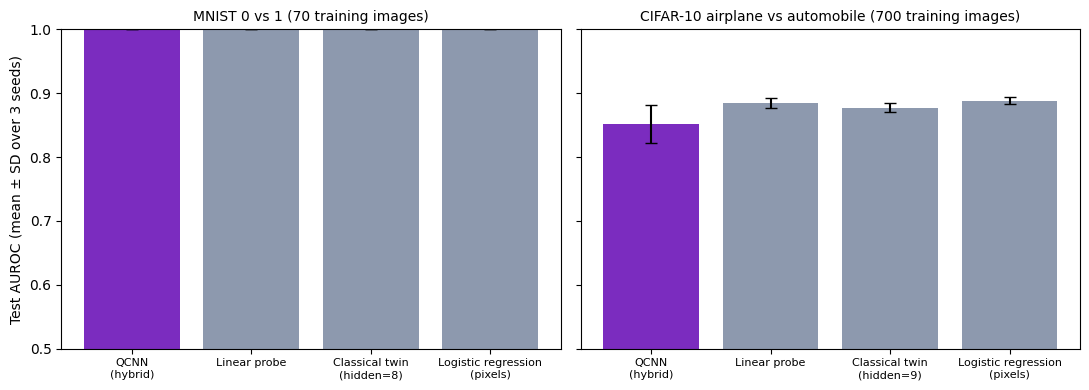

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, df) in zip(axes, [("MNIST 0 vs 1 (70 training images)", mnist), ("CIFAR-10 airplane vs automobile (700 training images)", cifar)]):
    s = df.groupby("model", sort=False)["test_auroc"].agg(["mean", "std"])
    colors = ["#7b2cbf" if m.startswith("QCNN") else "#8d99ae" for m in s.index]
    ax.bar(range(len(s)), s["mean"], yerr=s["std"], color=colors, capsize=4)
    ax.set_xticks(range(len(s)))
    ax.set_xticklabels([m.replace(" (", "\n(") for m in s.index], fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0.5, 1.0)
axes[0].set_ylabel("Test AUROC (mean ± SD over 3 seeds)")
plt.tight_layout()
fig.savefig("qcnn_results.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
pd.concat([mnist, cifar]).to_csv("qcnn_results_per_seed.csv", index=False)

## 8. What this demo shows — and what it does not

**Results (test AUROC, mean ± SD over 3 seeds, 1,000 test images per seed)**
- *MNIST 0 vs 1:* every model reaches ≈1.0, including the QCNN (0.9999 ± 0.0001). The task is too easy to separate the models: the classical layer that feeds the circuit already solves it on its own (linear probe 1.000).
- *CIFAR-10 airplane vs automobile:* QCNN 0.852 ± 0.030; classical twin 0.877 ± 0.007 (73 parameters in the part that differs, against 77 for the quantum part); linear probe 0.884 ± 0.008; logistic regression on pixels 0.888 ± 0.005. Here the quantum circuit does not add to what its classical layer already provides, and it varies more across seeds.

**What it shows**
- A quantum circuit can be trained end to end inside an ordinary PyTorch model, with automatic gradients, exactly like any other layer.
- Most trainable parameters of this hybrid model are classical: 3,140 (MNIST) and 18,438 (CIFAR-10) in the compression layer, against 47 and 77 in the quantum part.
- A fair test needs classical models of the same size and enough test data. With the original 15 test images, these differences could not have been seen.

**What it does not show**
- A quantum advantage: none of the comparisons favours the quantum circuit.
- Behaviour on real quantum hardware. The circuit was simulated without noise; simulation also made training about 5 times (MNIST) to 20 times (CIFAR-10) slower than for the classical twin.